In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

# Import experiment_config2 (sometimes at a level up)
cwd = Path.cwd()
while not (cwd / "experiment_config2.py").exists():
    cwd = cwd.parent
sys.path.insert(0, str(cwd))
from experiment_config3 import Config

# Import color map
cwd = Path.cwd()
while not (cwd / "color_map.py").exists():
    cwd = cwd.parent
sys.path.insert(0, str(cwd))
from color_map import make_color_map


import analysis_functions as af  # import all functions from analysis_functions.py

base_path = Path(
    "J:/sequences/1007_sequences"
)

sequences = Config.from_file(
    base_path
)

print(sequences)


pqif_vector = sequences.pqif_numbers


color_map_vreset = make_color_map(pqif_vector[1:-1], plt.cm.Reds)
# color_map_pqif = make_color_map(pqif_vector[1:-1], plt.cm.Greens)
color_map_pqif = {}
color_map_pqif[pqif_vector[0]] = 'black'
color_map_pqif[pqif_vector[1]] = plt.cm.Greens(0.8)
color_map_pqif[pqif_vector[-1]] = 'steelblue'

Config name: 1007_sequences
  target: sequences
  pqif: [0, 0.5, 1]
  simulations: 1: vt=0, vreset=-8.5, 2: vt=0, vreset=-12.3, 3: vt=0, vreset=-17, 4: vt=0, vreset=-22
  seeds: 20
  sequence conditions: 27
  amplitudes: [2.0, 4.0, 6.0]
  sigmas: [10.0, 15.0, 20.0]
  offsets: [0.0, 1.0, 2.0]
  base path: J:\sequences\1007_sequences


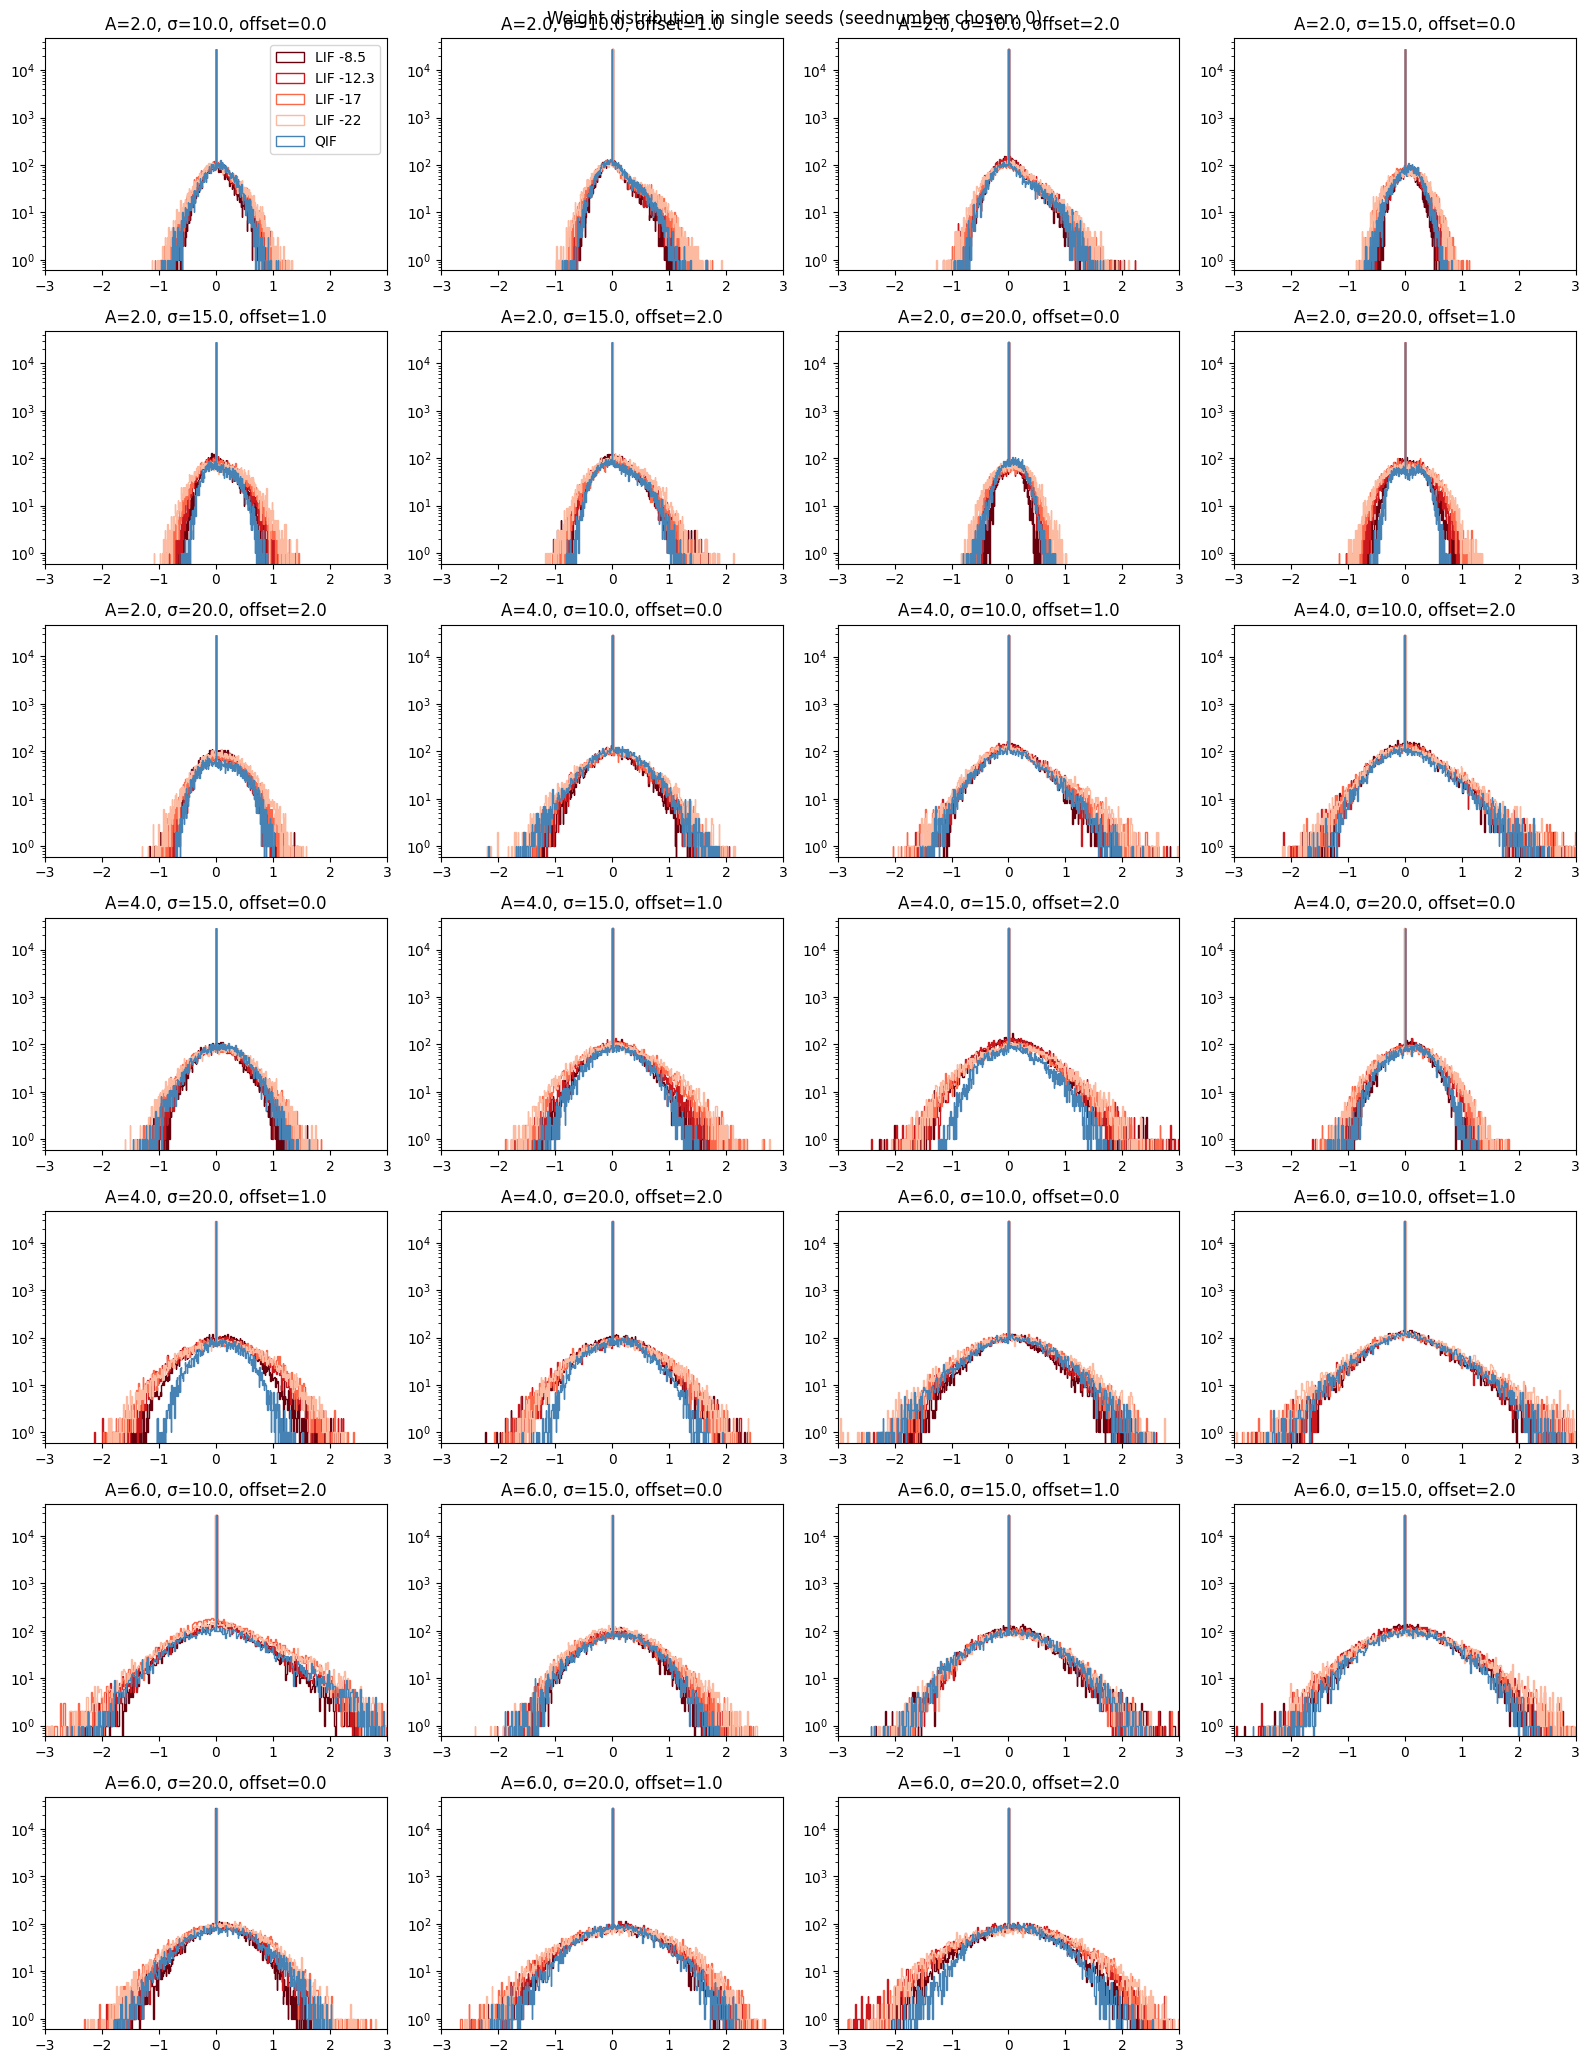

In [11]:
# Should ideally compute a shared min and max here for the x-axis, now it is hardcoded

xmin = -3
xmax = 3

vreset_vector = sequences.vresets
color_map_vreset = make_color_map(vreset_vector, plt.cm.Reds)

chosen_seed = 0


max_cols = 4
n_conditions = len(sequences.sequence_conditions)
ncols = min(max_cols, n_conditions)
nrows = int(np.ceil(n_conditions / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), squeeze=False)
axes = axes.flatten()

for i, condition in enumerate(sequences.sequence_conditions):

    ax = axes[i]

    for sim in sequences.sims:

        connectivity_path = sequences.path("connectivity", sim=sim, condition=condition)
        W = af.load_W(connectivity_path, sim=sim.sim, pqif=0, seed=chosen_seed)
        ax.hist(W.flatten(), bins="auto", histtype="step", log=True, color=color_map_vreset[sim.vreset], label=f"LIF {sim.vreset}")
        ax.set_xlim(xmin, xmax)

    # QIF
    sim = sequences.sims[0]
    connectivity_path = sequences.path("connectivity", sim=sim, condition=condition)
    W = af.load_W(connectivity_path, sim=sim.sim, pqif=1, seed=chosen_seed)
    ax.hist(W.flatten(), bins="auto", histtype="step", log=True, color="steelblue", label="QIF")
    ax.set_title(f"A={condition.amplitude}, σ={condition.sigma}, offset={condition.offset}")
    ax.set_xlim(xmin, xmax)

for ax in axes[n_conditions:]:
    ax.remove()

axes[0].legend()
plt.suptitle(f"Weight distribution in single seeds (seednumber chosen: {chosen_seed})")
plt.tight_layout()
plt.show()

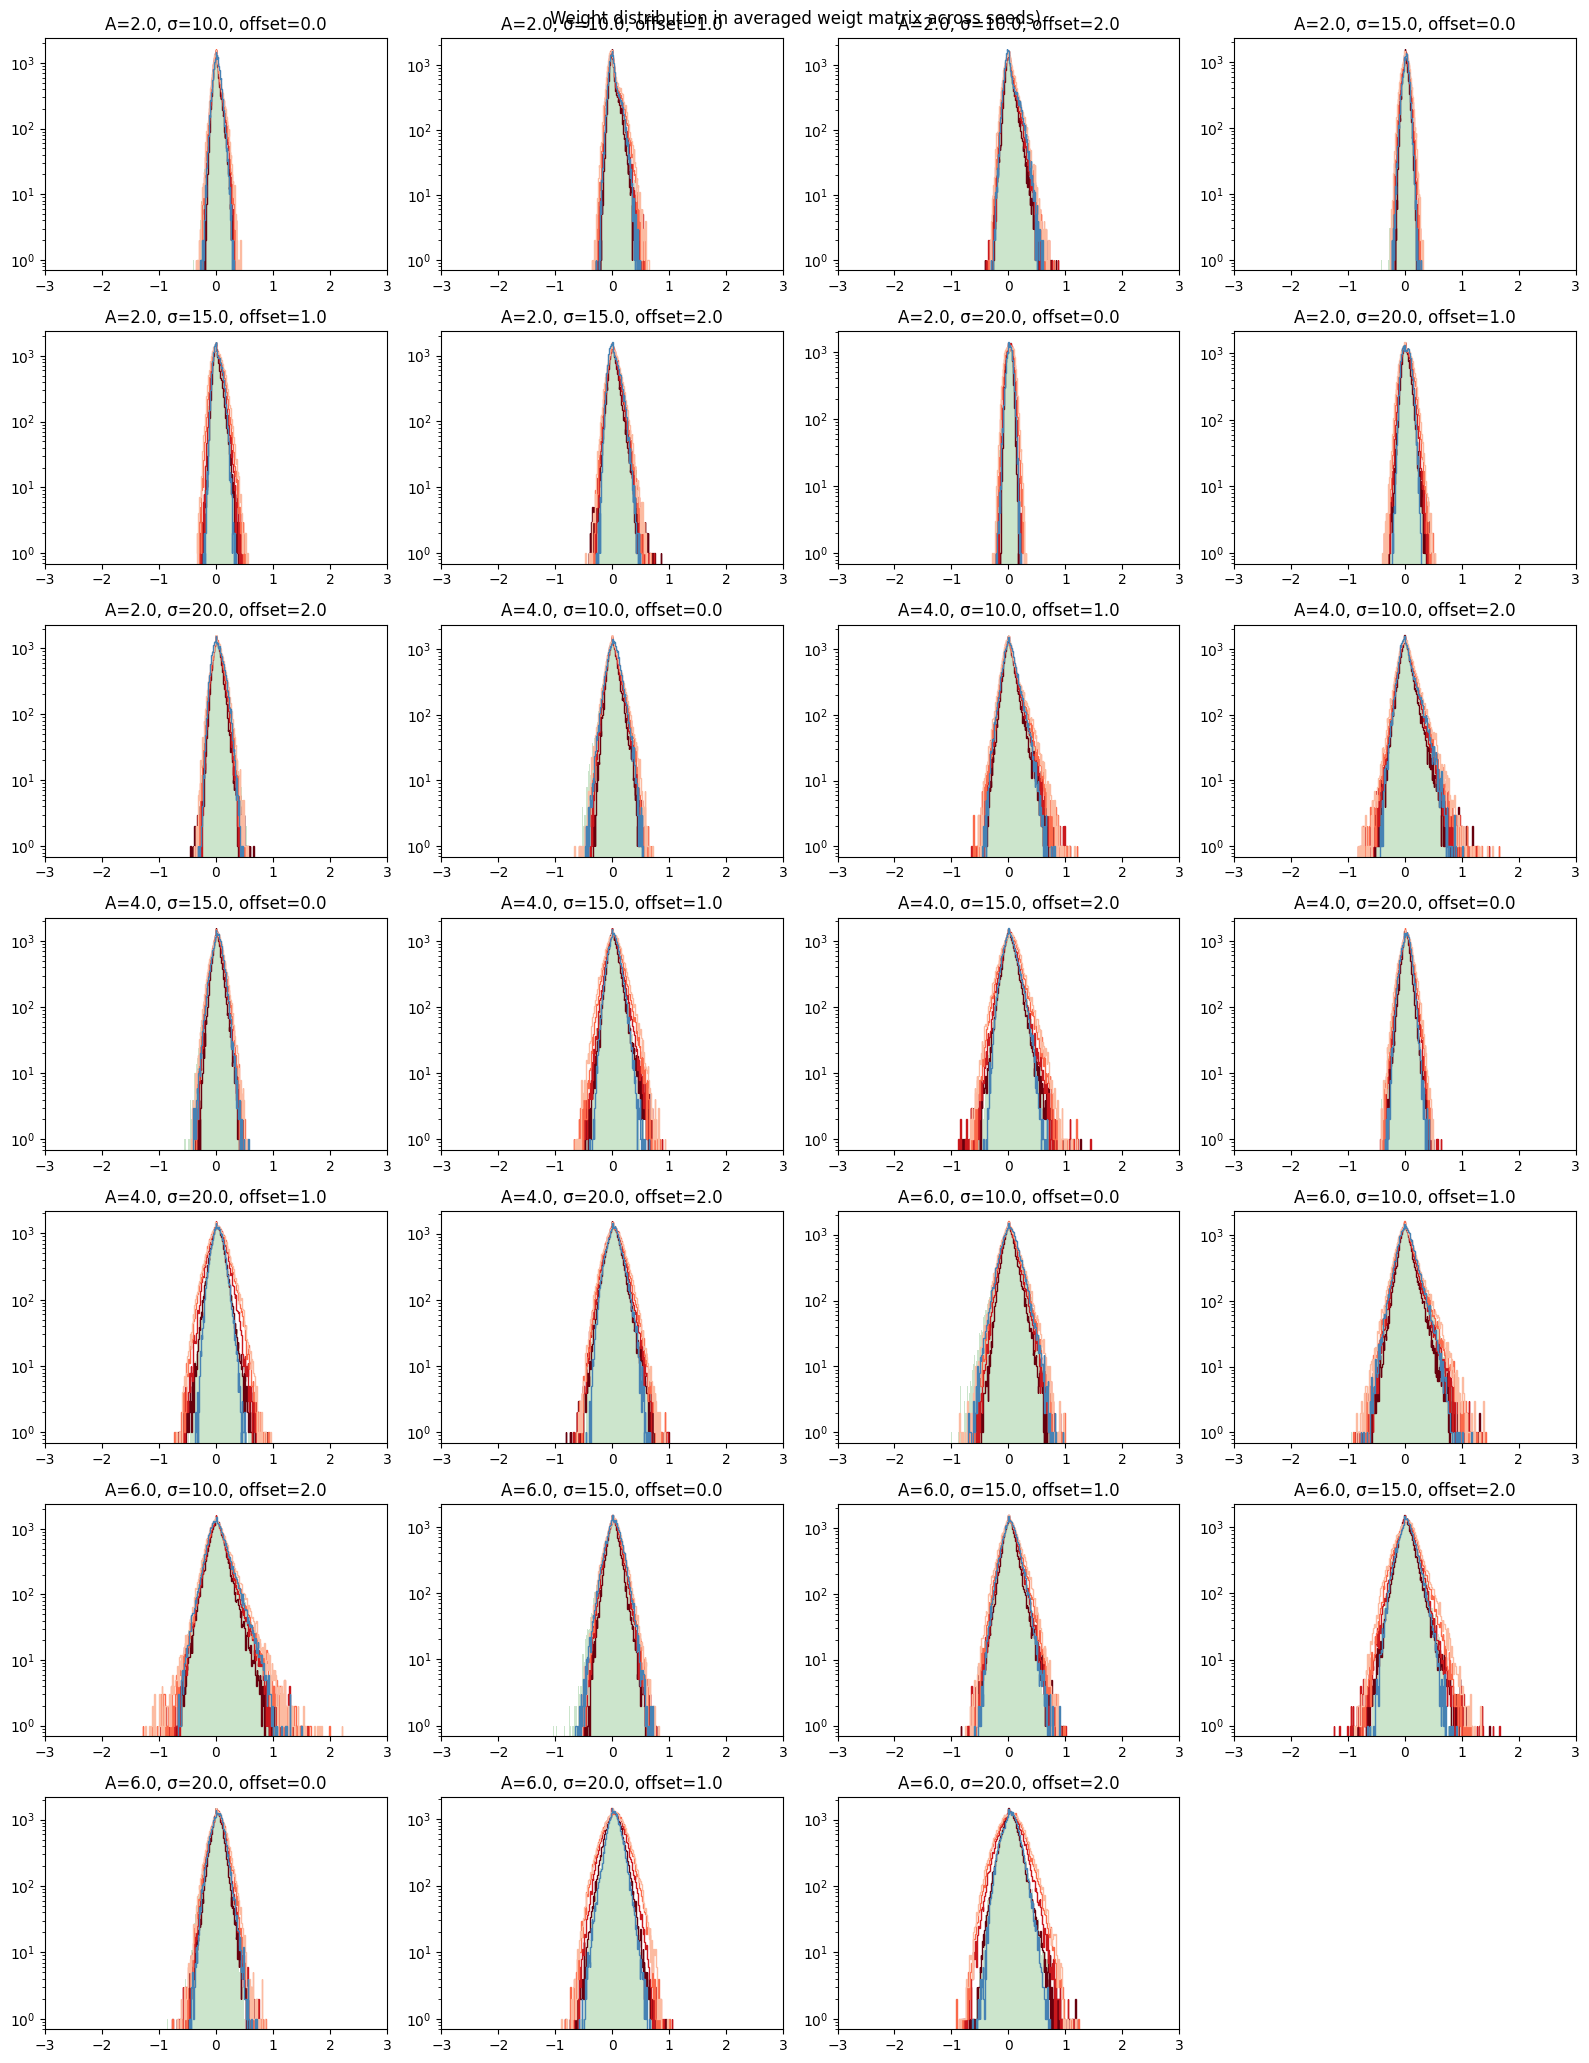

In [ ]:
# Distribution of mean connectivity

xmin = -3
xmax = 3

vreset_vector = sequences.vresets
color_map_vreset = make_color_map(vreset_vector, plt.cm.Reds)
color_map_sims = make_color_map(sequences.sim_numbers, plt.cm.Reds)

chosen_seed = 0


max_cols = 4
n_conditions = len(sequences.sequence_conditions)
ncols = min(max_cols, n_conditions)
nrows = int(np.ceil(n_conditions / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), squeeze=False)
axes = axes.flatten()

rows = []

for i, condition in enumerate(sequences.sequence_conditions):

    ax = axes[i]
    

    # if pqif == 0:
    #     color = color_map_vreset[sim.vreset]
    # elif pqif == 1:
    #     color = "steelblue"
    # else:
    #     color = "green"

    #     vresets = sequences.vresets

        
    seedrange = sequences.seed_numbers
    for sim in sequences.sims:

        # Get mean W for LIFs
        connectivity_path = sequences.path("connectivity", sim=sim, condition=condition)
        mean_W, mean_W_mean_weights, mean_W_std_weights = af.average_connectivity(connectivity_path, sim=sim.sim, pqif=0, seedrange=seedrange)

        ax.hist(mean_W.flatten(), bins="auto", histtype="step", log=True, color=color_map_vreset[sim.vreset], label=f"LIF {sim.vreset}")

    # QIF
    connectivity_path = sequences.path("connectivity", sim=1, condition=condition)
    mean_W, mean_W_mean_weights, mean_W_std_weights = af.average_connectivity(connectivity_path, sim=1, pqif=1, seedrange=seedrange)
    ax.hist(mean_W.flatten(), bins="auto", histtype="step", log=True, color="steelblue", label=f"LIF {sim.vreset}")



    # Example mix
    connectivity_path = sequences.path("connectivity", sim=3, condition=condition)
    mean_W, mean_W_mean_weights, mean_W_std_weights = af.average_connectivity(connectivity_path, sim=3, pqif=0.5, seedrange=seedrange)
    ax.hist(mean_W.flatten(), bins="auto", histtype="stepfilled", alpha=0.2, log=True, color="green", label=f"LIF {sim.vreset}")



    ax.set_title(f"A={condition.amplitude}, σ={condition.sigma}, offset={condition.offset}")
    ax.set_xlim(xmin, xmax)

for ax in axes[n_conditions:]:
    ax.remove()

# axes[0].legend()
plt.suptitle(f"Weight distribution in averaged weigt matrix across seeds)")
plt.tight_layout()
plt.show()
        


        

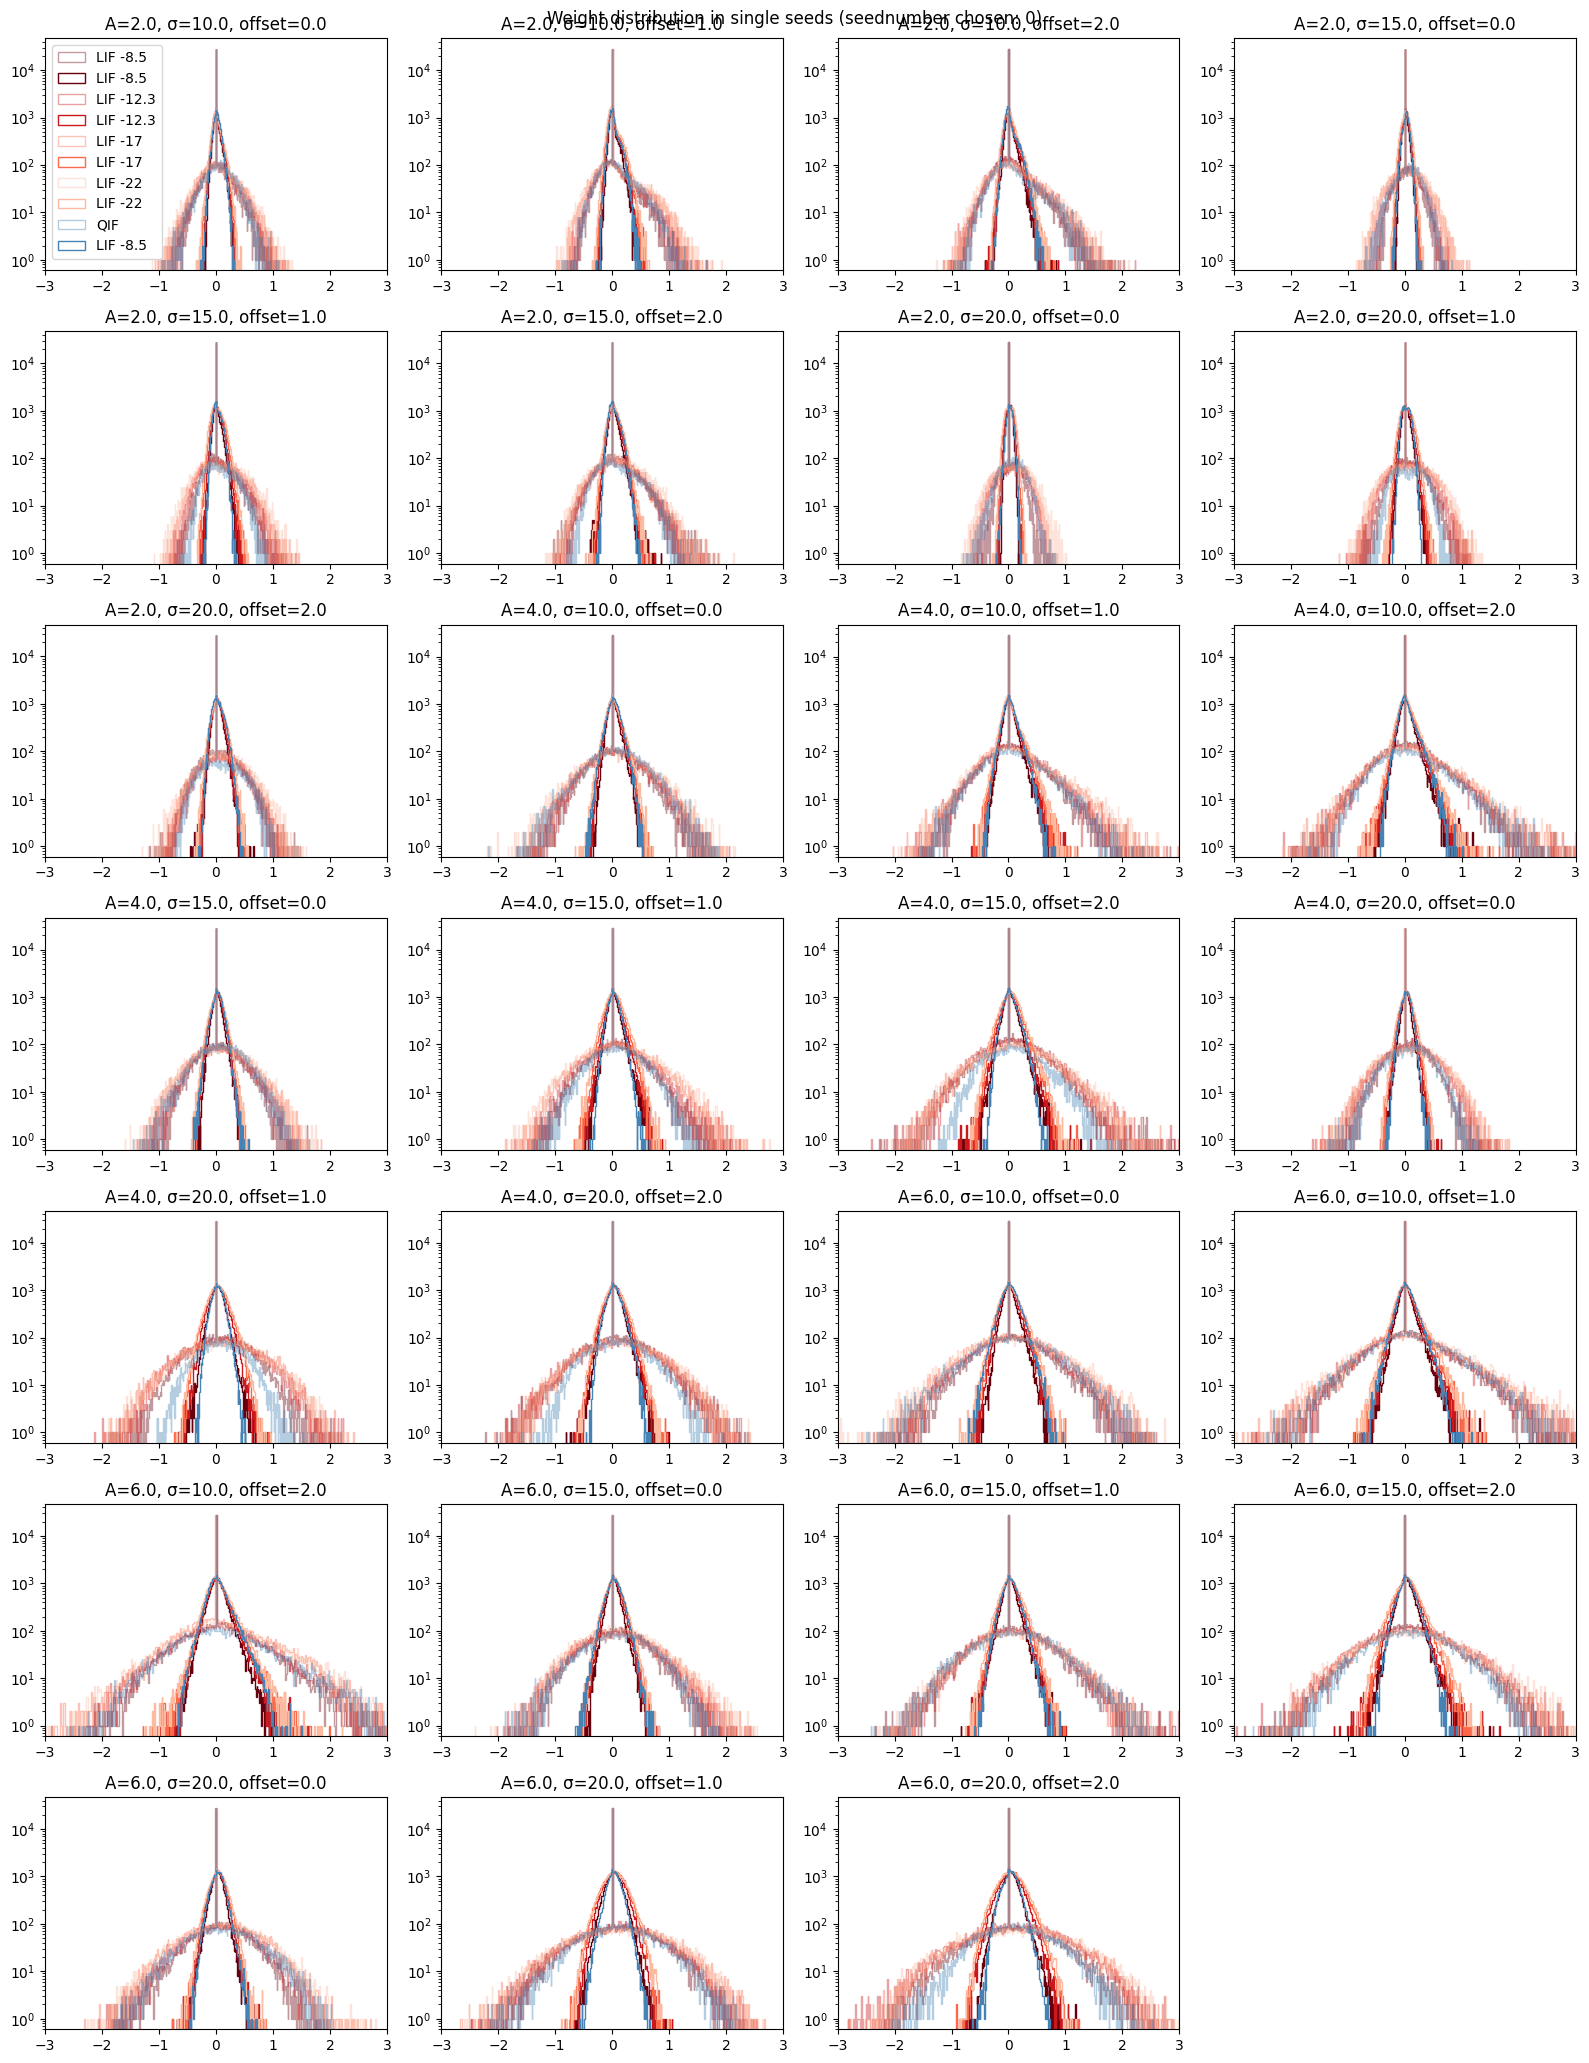

In [11]:
# Both

# Should ideally compute a shared min and max here for the x-axis, now it is hardcoded

xmin = -3
xmax = 3

vreset_vector = sequences.vresets
color_map_vreset = make_color_map(vreset_vector, plt.cm.Reds)

chosen_seed = 0


max_cols = 4
n_conditions = len(sequences.sequence_conditions)
ncols = min(max_cols, n_conditions)
nrows = int(np.ceil(n_conditions / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), squeeze=False)
axes = axes.flatten()

for i, condition in enumerate(sequences.sequence_conditions):

    ax = axes[i]

    for sim in sequences.sims:

        # LIF Single seed
        connectivity_path = sequences.path("connectivity", sim=sim, condition=condition)
        W = af.load_W(connectivity_path, sim=sim.sim, pqif=0, seed=chosen_seed)
        ax.hist(W.flatten(), bins="auto", histtype="step", log=True, color=color_map_vreset[sim.vreset], alpha=0.4, label=f"LIF {sim.vreset}")
        ax.set_xlim(xmin, xmax)


        # LIF average across seeds
        connectivity_path = sequences.path("connectivity", sim=sim, condition=condition)
        mean_W, mean_W_mean_weights, mean_W_std_weights = af.average_connectivity(connectivity_path, sim=sim.sim, pqif=0, seedrange=seedrange)
        ax.hist(mean_W.flatten(), bins="auto", histtype="step", log=True, color=color_map_vreset[sim.vreset], label=f"LIF {sim.vreset}")

    # QIF
    sim = sequences.sims[0]
    connectivity_path = sequences.path("connectivity", sim=sim, condition=condition)
    W = af.load_W(connectivity_path, sim=sim.sim, pqif=1, seed=chosen_seed)
    ax.hist(W.flatten(), bins="auto", histtype="step", log=True, color="steelblue", alpha=0.4, label="QIF")

    # QIF average across seeds
    connectivity_path = sequences.path("connectivity", sim=1, condition=condition)
    mean_W, mean_W_mean_weights, mean_W_std_weights = af.average_connectivity(connectivity_path, sim=1, pqif=1, seedrange=seedrange)
    ax.hist(mean_W.flatten(), bins="auto", histtype="step", log=True, color="steelblue", label=f"LIF {sim.vreset}")


    ax.set_title(f"A={condition.amplitude}, σ={condition.sigma}, offset={condition.offset}")
    ax.set_xlim(xmin, xmax)

for ax in axes[n_conditions:]:
    ax.remove()

axes[0].legend()
plt.suptitle(f"Weight distribution in single seeds (seednumber chosen: {chosen_seed})")
plt.tight_layout()
plt.show()

In [ ]:
# Distribution of weights where we subtract the mean connectivity from each individual seed



In [15]:
# Stats
import pandas as pd

results = []

for i, condition in enumerate(sequences.sequence_conditions):
        
    seedrange = sequences.seed_numbers

    for params in sequences.iter_params("sim", "pqif"):
        sim = params["sim"]
        pqif = params["pqif"]

        # Get mean W stats
        connectivity_path = sequences.path("connectivity", sim=sim, condition=condition)
        mean_W, mean_W_mean_weights, mean_W_std_weights = af.average_connectivity(connectivity_path, sim=sim.sim, pqif=pqif, seedrange=seedrange)

        results.append({
            "condition": condition,
            "sim": sim.sim,
            "pqif": pqif,
            "mean_W_mean_weights": mean_W_mean_weights,
            "mean_W_std_weights": mean_W_std_weights,
        })

df = pd.DataFrame(results)
df

,condition,sim,pqif,mean_W_mean_weights,mean_W_std_weights
0,"SequenceParam(condition_id=0, amplitude=2.0, s...",1,0.0,0.007735,0.061506
1,"SequenceParam(condition_id=0, amplitude=2.0, s...",1,0.5,0.009103,0.065064
2,"SequenceParam(condition_id=0, amplitude=2.0, s...",1,1.0,0.013592,0.064222
3,"SequenceParam(condition_id=0, amplitude=2.0, s...",2,0.0,0.008678,0.069891
4,"SequenceParam(condition_id=0, amplitude=2.0, s...",2,0.5,0.009962,0.068702
...,...,...,...,...,...
319,"SequenceParam(condition_id=26, amplitude=6.0, ...",3,0.5,0.036978,0.159734
320,"SequenceParam(condition_id=26, amplitude=6.0, ...",3,1.0,0.035674,0.145342
321,"SequenceParam(condition_id=26, amplitude=6.0, ...",4,0.0,0.042994,0.232708
322,"SequenceParam(condition_id=26, amplitude=6.0, ...",4,0.5,0.040033,0.165741


C:\Users\snrambo\AppData\Local\Temp\ipykernel_18976\1573283157.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()


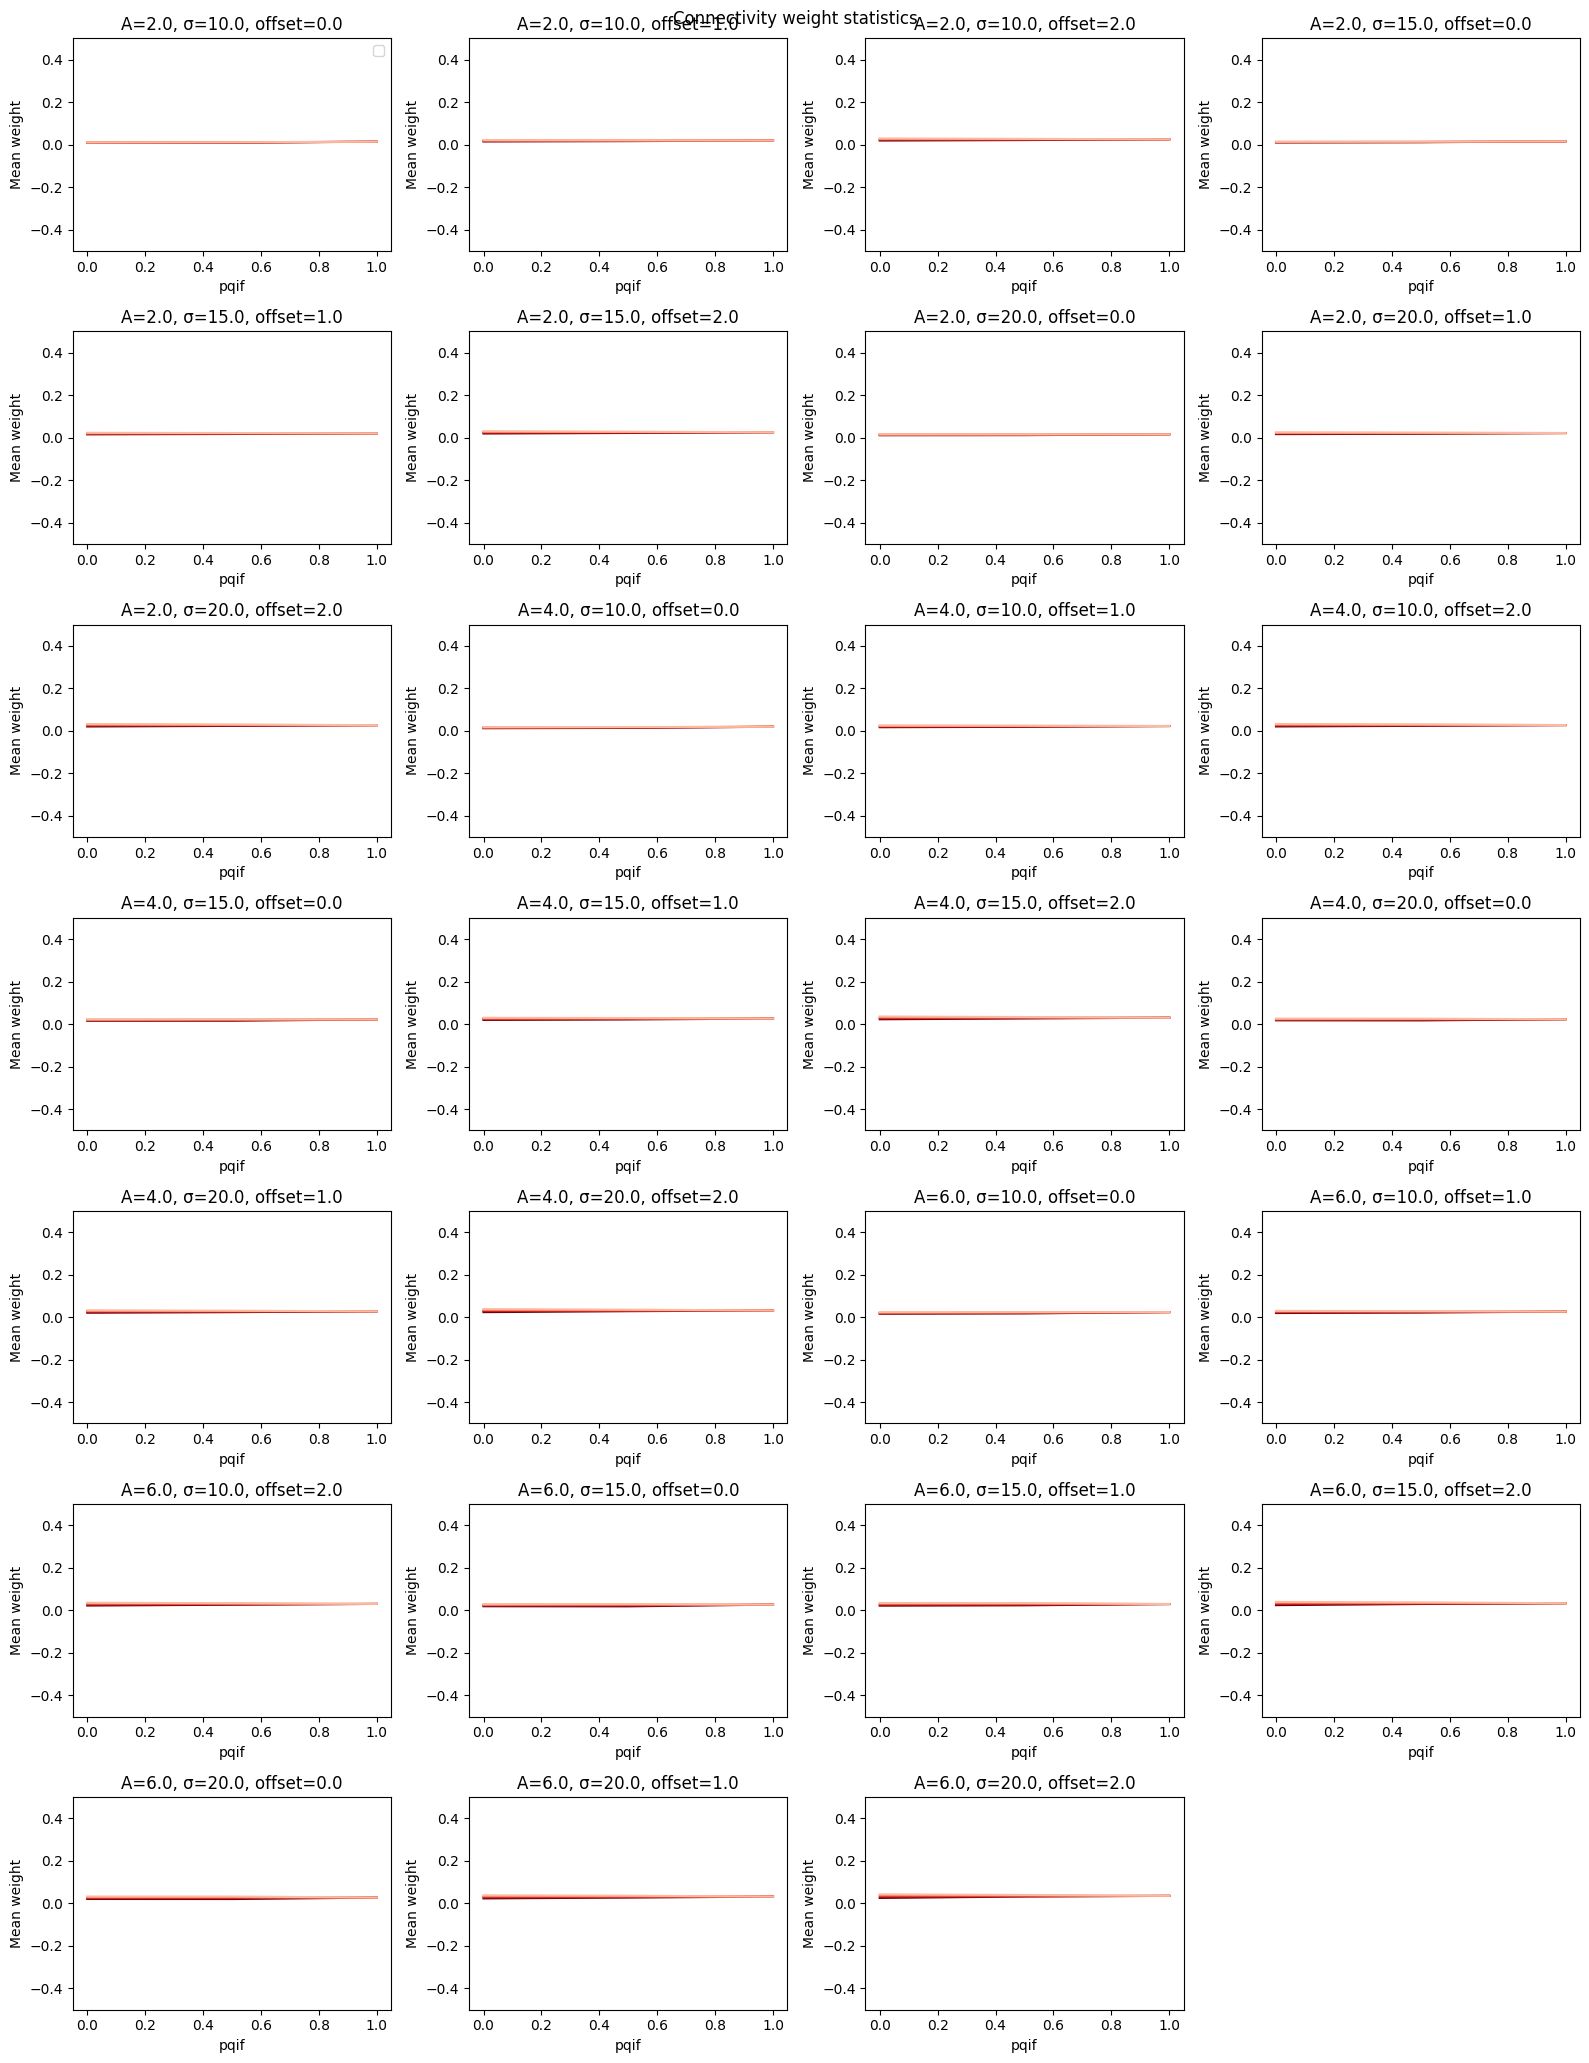

In [20]:
max_cols = 4
n_conditions = len(sequences.sequence_conditions)
ncols = min(max_cols, n_conditions)
nrows = int(np.ceil(n_conditions / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows), squeeze=False)
axes = axes.flatten()

for i, condition in enumerate(sequences.sequence_conditions):
    ax = axes[i]
    for sim in sequences.sims:
        df_filtered = df[(df["condition"] == condition) & (df["sim"] == sim.sim)].sort_values("pqif")
        # ax.errorbar(df_filtered["pqif"], df_filtered["mean_W_mean_weights"], yerr=df_filtered["mean_W_std_weights"], marker="o", label=f"Vreset={sim.vreset}")
        ax.plot(df_filtered["pqif"], df_filtered["mean_W_mean_weights"], color=color_map_vreset[sim.vreset])
    ax.set_title(f"A={condition.amplitude}, σ={condition.sigma}, offset={condition.offset}")
    ax.set_xlabel("pqif")
    ax.set_ylabel("Mean weight")
    ax.set_ylim(-0.5, 0.5)

for ax in axes[n_conditions:]:
    ax.remove()

axes[0].legend()
plt.suptitle("Connectivity weight statistics")
plt.tight_layout()
plt.show()